# Non-ideal current interrupt

This tutorial is similar to [3_eis.ipynb](3_eis.ipynb). It adds an external RLC circuit to calculate the current after interruption instead of forcing it instantly to zero.

The added circuit introduces two states: current `I(t)` and capacitor voltage `V_C(t)`, coupled to the cell model.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display

from nest.boundary import BoundaryData
from nest.cell import Cell, ChannelGeometry
from nest.constants import R
from nest.layers import ButlerVolmer, Conductivity, Layer, PorousTransport
from nest.properties import BasicSpecies, Mixture
from nest.eis import (
    Model, ExternalCircuit, solve_steady, solve_transient,
    current_interrupt, impedance, plot_impedance, save_results,
)


## 2. Defining the cell

### 2.1. Porous media

In [2]:
# Transport parameters used by eis_fitting.make_cell.
# dp: mean pore diameter [m]; epsilon: gas porosity [-]; tau: gas tortuosity [-].
fuel_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=1.23 * (1 - 0.30)**(4 / 3) / 0.30)
air_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=1.23 * (1 - 0.30)**(4 / 3) / 0.30)
support_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=1.23 * (1 - 0.30)**(4 / 3) / 0.30)


### 2.2. Fuel and air electrodes

In [3]:
# Effective electrode ionic conductivity includes ionic-phase fraction/tortuosity.
# sigma(T) = sigma0 * T**theta * exp(-E_act/(R*T)); sigma0 is the conductivity prefactor.
# Exchange current per TPB length uses i0 = A_r*T**theta*exp(-Ea/RT)*pressure_factor.
# A_r is supplied later as kinetic.exchange_current_prefactor; kinetic.gamma is not used by this model.
fuel_ionic_fraction = 0.58 * (1.0 - fuel_transport.epsilon)  # Fraction of total electrode volume [-].
fuel_ionic_tortuosity = 2.8  # Ionic tortuosity [-], distinct from gas tortuosity.

fuel = Layer(
    delta=10e-6,        # Fuel-electrode thickness [m].
    transport=fuel_transport,
    kinetic=ButlerVolmer(
        gas=Mixture((BasicSpecies.H2, BasicSpecies.H2O)),  # Species order for nu and p.
        nu=[-1.0, 1.0],         # H2 consumed; H2O produced (fuel-cell direction) [-].
        n_e=2,                  # Electrons transferred per half-reaction [-].
        alpha=0.59,             # Forward charge-transfer coefficient [-].
        beta=0.41,              # Reverse charge-transfer coefficient [-].
        p=[-0.10, 0.33],        # H2 and H2O exponents for exchange current [-].
        theta=1,                # Temperature exponent for exchange current [-].
        E_act=1.62e5,           # Reaction activation energy [J/mol].
    ),
    conductivity=Conductivity(
        sigma0=3.6e7 * fuel_ionic_fraction / fuel_ionic_tortuosity,  # Effective conductivity prefactor.
        E_act=80e3,             # Ionic-conduction activation energy [J/mol].
        theta=-1,               # Temperature exponent for ionic conductivity [-].
    ),
)

# Air-electrode ionic fraction can differ from the fuel-electrode value.
air_ionic_fraction = 0.50 * (1.0 - air_transport.epsilon)  # Fraction of total volume [-].
air_ionic_tortuosity = 1.8  # Ionic-phase tortuosity [-].

air = Layer(
    delta=30e-6,        # Air-electrode thickness [m].
    transport=air_transport,
    kinetic=ButlerVolmer(
        gas=Mixture((BasicSpecies.O2, BasicSpecies.N2)),  # Species order for nu and p.
        nu=[-0.5, 0.0],         # O2 consumed; N2 inert (fuel-cell direction) [-].
        n_e=2,                  # Electrons transferred per half-reaction [-].
        alpha=0.65,             # Forward charge-transfer coefficient [-].
        beta=0.35,              # Reverse charge-transfer coefficient [-].
        p=[0.22, 0.0],          # O2 and N2 exponents for exchange current [-].
        theta=1,                # Temperature exponent for exchange current [-].
        E_act=1.57e5,           # Reaction activation energy [J/mol].
    ),
    conductivity=Conductivity(
        sigma0=1.09e7 * air_ionic_fraction / air_ionic_tortuosity,  # Effective conductivity prefactor.
        E_act=61.75e3,          # Ionic-conduction activation energy [J/mol].
        theta=-1,               # Temperature exponent for ionic conductivity [-].
    ),
)


### 2.3. Electrolyte layers

In [4]:
# Rounded ohmic parameters from eis_compare.py and eis_fitting.make_cell.
# Each electrolyte-like layer contributes an ohmic resistance delta / sigma(T).
# Conductivity(T) = sigma0 * T**theta * exp(-E_act / (R*T)).
electrolyte = (
    Layer(
        delta=12e-6,  # YSZ thickness [m].
        conductivity=Conductivity(sigma0=3.6e7, E_act=80e3, theta=-1),
    ),
    Layer(
        delta=8e-6,   # CGO thickness [m].
        conductivity=Conductivity(sigma0=1.09e7, E_act=61.75e3, theta=-1),
    ),
    Layer(
        delta=3.04e-7,   # CGO/YSZ interdiffusion-layer thickness [m].
        conductivity=Conductivity(sigma0=0.2312, E_act=7.31e4, theta=1),
    ),
)

### 2.4. Cell definition

In [5]:
# Active electrochemical area [m²]; independent of channel cross-section.
cell = Cell(
    area=0.04 * 0.04,
    electrode_fuel=fuel,
    electrode_air=air,
    electrolyte=electrolyte,
)

### 2.5. EIS parameters

The existing `Cell`, `Layer`, and `Kinetic` objects store the inputs needed for impedance calculations, which include:
1. Electrode reaction and capacitance parameters 
2. **Channel geometries** and **fuel support** as their gas transport and storage affect the transient response (support has no electrochemical reaction).

In [6]:
# Rounded fitted values from eis_compare.py; capacitance is given per electrode volume [F/m³].
fuel.tpb_density = 2.06e12          # TPB length per electrode volume [m^-2].
fuel.kinetic.exchange_current_prefactor = 68.0  # A_r [A/(m K^theta)], TPB-based kinetics.
fuel.capacitance_volumetric = 6.76e5  # [F/m³].
air.tpb_density = 1.82e12          # TPB length per electrode volume [m^-2].
air.kinetic.exchange_current_prefactor = 38.5  # A_r [A/(m K^theta)], TPB-based kinetics.
air.capacitance_volumetric = 5.89e7  # [F/m³].
# Channel length along the flow, width across flow, and height [m].
cell.fuel_channel = ChannelGeometry(length=0.04, width=0.04, height=1e-3)
cell.air_channel = ChannelGeometry(length=0.04, width=0.04, height=1e-3)
cell.fuel_support = Layer(
    delta=300e-6,  # Fuel support thickness [m]; explicitly meshed.
    transport=support_transport,  # Support has gas storage/transport, no reaction.
)

### 2.6. Operating conditions and numerical grid

In [7]:
# Inlet flows are specified as litres/hour at 273.15 K and 1 bar.
# Conversion factor: (L/h) -> (m³/s) -> (mol/s), using the ideal gas law.
flow_factor = 1e5 * 1e-3 / (3600 * R * 273.15)  # [mol/s per (L/h)].

boundary = BoundaryData(
    T=807 + 273.15,               # Isothermal operating temperature [K].
    P=101325.0,                  # Boundary reference pressure [Pa].
    fuel_pressure=101325.0,   # Fuel-side absolute pressure [Pa].
    air_pressure=101325.0,    # Air-side absolute pressure [Pa].
    n_fuel=flow_factor * 24.0 * np.array([0.50, 0.50]),  # H2/H2O molar inlet flows [mol/s].
    n_air=flow_factor * 50.0 * np.array([0.21, 0.79]),   # O2/N2 molar inlet flows [mol/s].
)

# Number of channel, fuel, air and support control volumes, respectively.
# This small grid is for demonstration; increase it for mesh-convergence studies.
model = Model(cell, boundary, n_x=10, n_zf=4, n_za=3, n_zs=2)

## 3. Steady-state simulation

The cell uses mean current density [A/m^2]; the external circuit uses total current [A].

In [8]:
# Initial zero-mean-current voltage estimate, based on inlet composition [V].
ocv = model.voltage_for_current(model.initial_state())
voltage_before = ocv + 50e-3  # Applied cell voltage [V].

steady = solve_steady(model, voltage_before)
current_profile = model.current_density(steady.x, voltage_before)
current_before = float(current_profile.mean())  # [A/m^2].
I_before = current_before * cell.area            # [A].

print(f"Initial OCV estimate: {ocv:.6f} V")
print(f"Steady cell voltage:  {voltage_before:.6f} V")
print(f"Mean current density: {current_before:.4f} A/m^2")
print(f"Total current:        {I_before:.6f} A")
print(f"Steady residual:      {steady.residual_norm:.3g} A/m^2")


Initial OCV estimate: 0.938911 V
Steady cell voltage:  0.988911 V
Mean current density: -2138.4198 A/m^2
Total current:        -3.421472 A
Steady residual:      6.29e-09 A/m^2


## 4. External circuit and voltage measurements

The circuit contains wiring resistance, shunt resistance, inductance, and capacitance.

$$
L\frac{dI}{dt}=V_\text{cell}-V_\text{source}-(R_\text{wire}+R_\text{shunt})I-V_C,
\qquad C\frac{dV_C}{dt}=I.
$$

Initially, the current equals its pre-interrupt value and the capacitor voltage is zero. We assume the source voltage balances the circuit before interruption and stays constant afterward.

The three figures show the same circuit with different voltage-sensing points. 

### Case 1: Cell only

<img src="figures/nonideal_interrupt_circuit_1.png" alt="Case 1: voltage across the cell" width="650">


### Case 2: Cell and inductance

<img src="figures/nonideal_interrupt_circuit_2.png" alt="Case 2: voltage across cell and inductance" width="650">


### Case 3: Cell, inductance, and wiring resistance

<img src="figures/nonideal_interrupt_circuit_3.png" alt="Case 3: voltage across cell, inductance and wiring resistance" width="650">



**Note**: Higher inductance can slow the simulation because oscillation can last longer, and the solver has to take small steps.

In [9]:
circuit = ExternalCircuit(
    inductance=1e-7,            # [H].
    wiring_resistance=0.0005,  # Illustrative wiring resistance [ohm].
    shunt_resistance=1,   # Illustrative shunt resistance [ohm].
    capacitance=1e-5,  # Effective switch capacitance [F].
)
source_voltage = voltage_before - circuit.resistance * I_before

print(f"Source voltage: {source_voltage:.6f} V")
print(f"LC time scale:  {np.sqrt(circuit.inductance * circuit.capacitance):.2e} s")


Source voltage: 4.412093 V
LC time scale:  1.00e-06 s


## 5. Solve ideal and non-ideal interrupts

In [10]:
interrupt = current_interrupt(current_before, at=0.0)
early_end = 1e-3  # First 1 millisecond.
times = np.unique(np.r_[
    np.linspace(0.0, early_end, 1001),
    np.geomspace(1e-9, 30.0, 1500),
])

ideal = solve_transient(
    model, interrupt, (0.0, times[-1]), initial_state=steady.x,
    t_eval=times, rtol=1e-6, atol=1e-8,
)
nonideal = solve_transient(
    model, interrupt, (0.0, times[-1]), initial_state=steady.x,
    t_eval=times, rtol=1e-6, atol=1e-8,
    circuit=circuit, source_voltage=source_voltage,
)

ideal_j = np.array([interrupt(t) for t in ideal.t])
ideal_voltage = np.array([
    model.voltage_for_current(state, j)
    for state, j in zip(ideal.y.T, ideal_j)
])
ideal_current = ideal_j * cell.area

# Use the solved current, not interrupt(t), for the non-ideal response.
nonideal_j = nonideal.current_density
nonideal_voltage = nonideal.voltage


## 6. Compare current and cell voltage

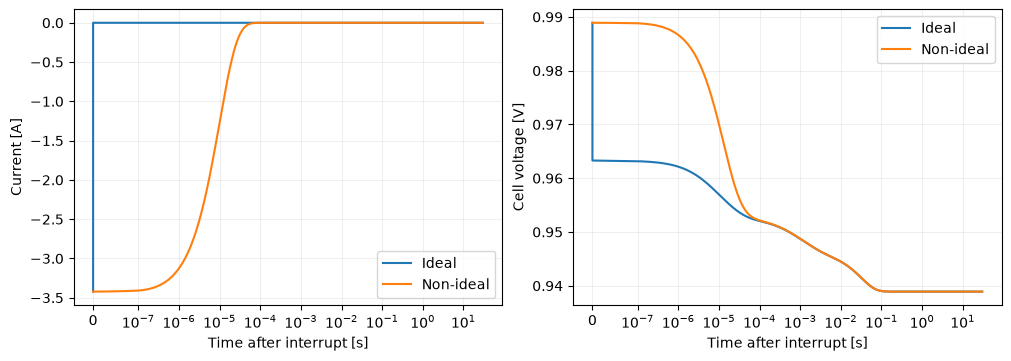

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained", sharex=True)
for label, result, current, voltage in (
    ("Ideal", ideal, ideal_current, ideal_voltage),
    ("Non-ideal", nonideal, nonideal.current, nonideal_voltage),
):
    plot_time = np.r_[0.0, result.t]
    axes[0].plot(plot_time, np.r_[I_before, current], label=label)
    axes[1].plot(plot_time, np.r_[voltage_before, voltage], label=label)

axes[0].set_ylabel("Current [A]")
axes[0].set_xlabel("Time after interrupt [s]")
axes[1].set_ylabel("Cell voltage [V]")
axes[1].set_xscale("symlog", linthresh=1e-7)
axes[1].set_xlabel("Time after interrupt [s]")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()


## 7. Calculate the three measured voltages

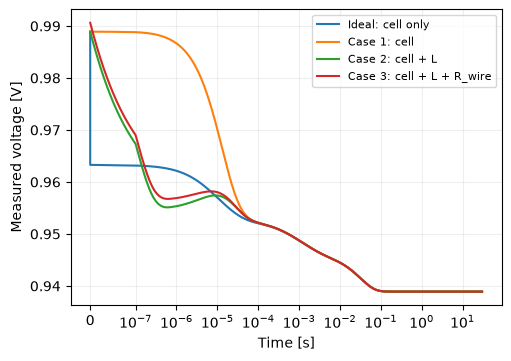

In [12]:
dcurrent_dt, _ = circuit.derivatives(
    nonideal.current, nonideal.capacitor_voltage,
    nonideal.voltage, source_voltage,
)
voltage_1 = nonideal.voltage
voltage_2 = nonideal.voltage - circuit.inductance * dcurrent_dt
voltage_3 = voltage_2 - circuit.wiring_resistance * nonideal.current

voltage_before_1 = voltage_before
voltage_before_2 = voltage_before
voltage_before_3 = voltage_before - circuit.wiring_resistance * I_before

fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
for label, t, voltage, initial_voltage in (
    ("Ideal: cell only", ideal.t, ideal_voltage, voltage_before),
    ("Case 1: cell", nonideal.t, voltage_1, voltage_before_1),
    ("Case 2: cell + L", nonideal.t, voltage_2, voltage_before_2),
    ("Case 3: cell + L + R_wire", nonideal.t, voltage_3, voltage_before_3),
):
    ax.plot(np.r_[0.0, t], np.r_[initial_voltage, voltage], label=label)

# ax.set_xlim(0, 1e-5)
ax.set_xscale("symlog", linthresh=1e-7)
ax.set(xlabel="Time [s]", ylabel="Measured voltage [V]")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.show()


## 8. Compare each impedance with the ideal interrupt

In [13]:
frequencies = np.geomspace(0.1, 1e6, 180)
Z_ideal = impedance(
    ideal.t, ideal_voltage, ideal_j, frequencies,
    voltage_before=voltage_before, current_before=current_before,
)

# Limit the inductive tail to keep the positive arc visible.
arc_height = np.nanmax(-Z_ideal.imag)
negative_tail_limit = -0.25 * arc_height
imaginary_ylim = (negative_tail_limit, 1.15 * arc_height)

# Limit Re(Z) to the ideal arc, with a small margin on each side.
real_min, real_max = np.nanmin(Z_ideal.real), np.nanmax(Z_ideal.real)
real_margin = 0.1 * (real_max - real_min)  # Adjustable margin [ohm m^2].
real_lim = (real_min - real_margin, real_max + real_margin)


### 8.1. Case 1: cell

No external voltage drop is included.


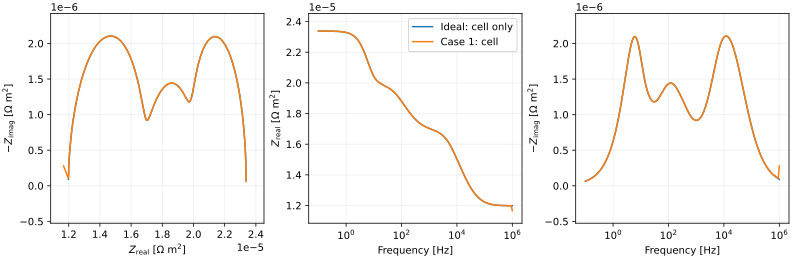

In [14]:
# make output directory for impedance plots
output = Path("5_nonideal_current_interrupt")
output.mkdir(parents=True, exist_ok=True)
Z_case_1 = impedance(
    nonideal.t, voltage_1, nonideal_j, frequencies,
    voltage_before=voltage_before_1, current_before=current_before,
)
comparison_1 = plot_impedance(
    {"Ideal: cell only": (frequencies, Z_ideal),
     "Case 1: cell": (frequencies, Z_case_1)},
    output / "impedance_case_1_vs_ideal.svg",
    imaginary_ylim=imaginary_ylim,
    real_lim=real_lim,
)
display(SVG(filename=str(comparison_1)))


### 8.2. Case 2: cell + L

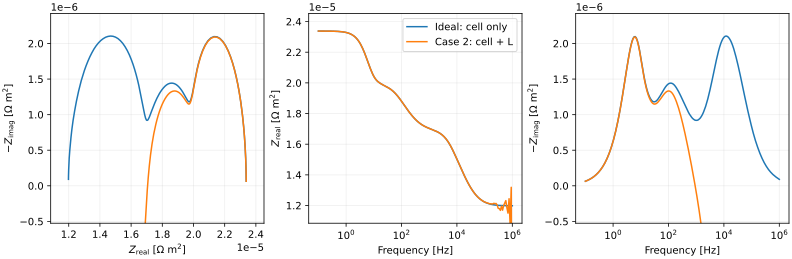

In [15]:
Z_case_2 = impedance(
    nonideal.t, voltage_2, nonideal_j, frequencies,
    voltage_before=voltage_before_2, current_before=current_before,
)
comparison_2 = plot_impedance(
    {"Ideal: cell only": (frequencies, Z_ideal),
     "Case 2: cell + L": (frequencies, Z_case_2)},
    output / "impedance_case_2_vs_ideal.svg",
    imaginary_ylim=imaginary_ylim,
    real_lim=real_lim,
)
display(SVG(filename=str(comparison_2)))


### 8.3. Case 3: cell + L + R_wire

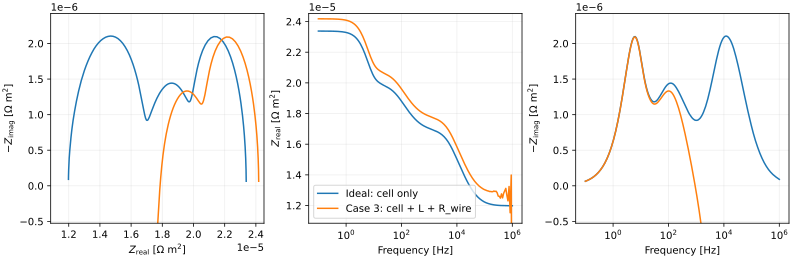

In [16]:
Z_case_3 = impedance(
    nonideal.t, voltage_3, nonideal_j, frequencies,
    voltage_before=voltage_before_3, current_before=current_before,
)
comparison_3 = plot_impedance(
    {"Ideal: cell only": (frequencies, Z_ideal),
     "Case 3: cell + L + R_wire": (frequencies, Z_case_3)},
    output / "impedance_case_3_vs_ideal.svg",
    imaginary_ylim=imaginary_ylim,
    real_lim=real_lim,
)
display(SVG(filename=str(comparison_3)))
